In [1]:
!nvidia-smi

import torch

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

Tue Oct 13 00:40:26 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   40C    P8             11W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [2]:
from google.colab import drive

drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [3]:
%cd /content

from pathlib import Path

if not Path("/content/GDBA_Net").exists():
    !git clone https://github.com/biplabpoudel25/GDBA_Net.git
else:
    print("GDBA_Net repository already exists.")

%cd /content/GDBA_Net

/content
GDBA_Net repository already exists.
/content/GDBA_Net


In [4]:
%pip install \
    hydra-core \
    tensorboardX==2.6.2.2 \
    einops \
    numpy==1.26.4 \
    Pillow \
    PyYAML==6.0.2 \
    tqdm==4.67.1 \
    opencv-python==4.11.0.86 \
    PyWavelets \
    scipy \
    scikit-learn \
    matplotlib \
    fsspec

In [5]:
import yaml
from pathlib import Path

config_path = Path("/content/GDBA_Net/configs/gdba_net.yaml")
inference_config = Path("/content/GDBA_Net/configs/gdba_inference.yaml")

with open(config_path, "r") as f:
    config = yaml.safe_load(f)

config["test_dataset"]["batch_size"] = 1
config["test_dataset"]["num_workers"] = 2

with open(inference_config, "w") as f:
    yaml.safe_dump(config, f, sort_keys=False)

print("Inference configuration created.")
print("Batch size:", config["test_dataset"]["batch_size"])
print("Workers:", config["test_dataset"]["num_workers"])
print("Input size:", config["test_dataset"]["wrapper"]["args"]["inp_size"])

Inference configuration created.
Batch size: 1
Workers: 2
Input size: 1024


In [6]:
from pathlib import Path

checkpoint = Path(
    "/content/drive/MyDrive/GDBA_Net_Colab/checkpoints/model_epoch_best.pth"
)

image_dir = Path(
    "/content/drive/MyDrive/GDBA_Net_Colab/datasets/MoNuSeg_80_20/test/images"
)

print("Checkpoint exists:", checkpoint.is_file())
print("Image directory exists:", image_dir.is_dir())

if image_dir.is_dir():
    images = [
        p for p in image_dir.iterdir()
        if p.suffix.lower() in
        {".png", ".jpg", ".jpeg", ".tif", ".tiff", ".bmp"}
    ]
    print("Total images:", len(images))

Checkpoint exists: True
Image directory exists: True
Total images: 11


In [7]:
%cd /content/GDBA_Net

!python inference.py \
    --config configs/gdba_inference.yaml \
    --model /content/drive/MyDrive/GDBA_Net_Colab/checkpoints/model_epoch_best.pth \
    --input /content/drive/MyDrive/GDBA_Net_Colab/datasets/MoNuSeg_80_20/test/images \
    --output_dir /content/gdba_inference_results/monuseg

/content/GDBA_Net
Device: cuda
Inference dataset: 11 images
Inside handcrafted features
Model loaded from: /content/drive/MyDrive/GDBA_Net_Colab/checkpoints/model_epoch_best.pth
Predicted masks saved to: /content/gdba_inference_results/monuseg


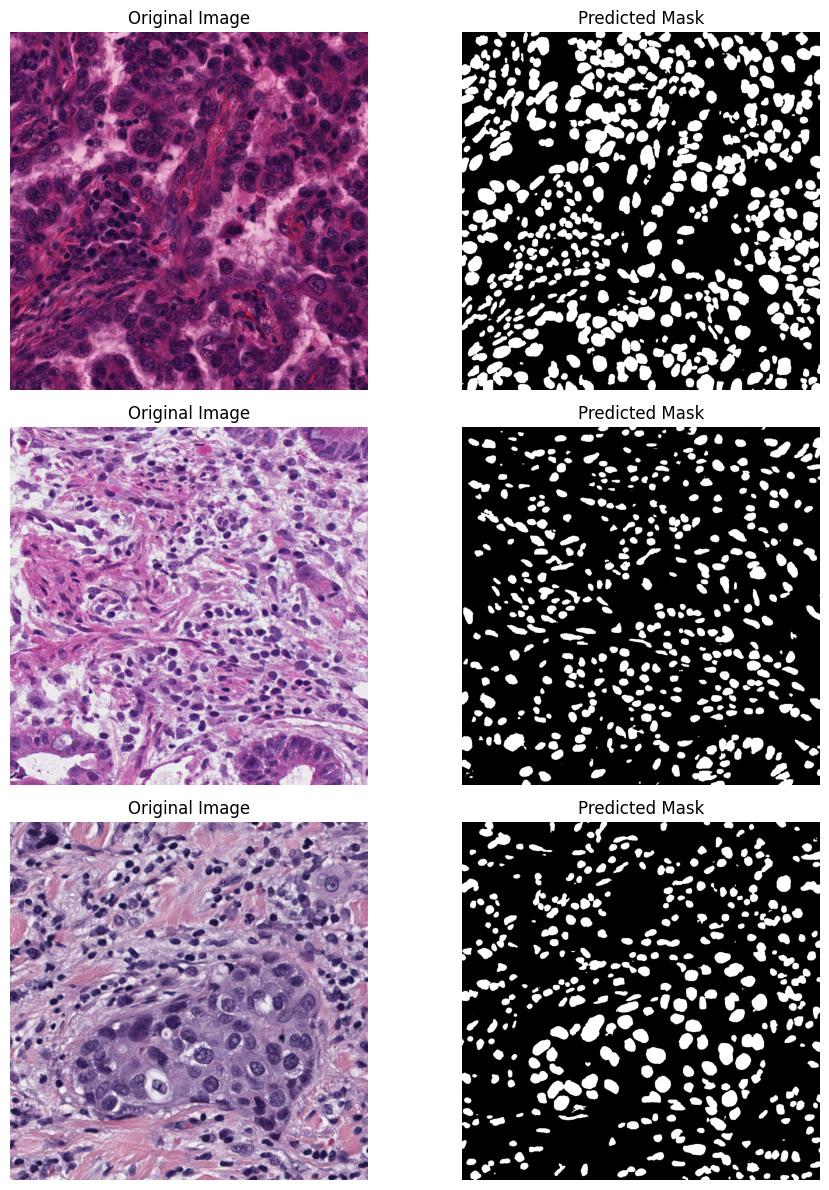

In [8]:
from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt

image_dir = Path(
    "/content/drive/MyDrive/GDBA_Net_Colab/datasets/MoNuSeg_80_20/test/images"
)

output_dir = Path("/content/gdba_inference_results/monuseg")

image_files = sorted([
    p for p in image_dir.iterdir()
    if p.suffix.lower() in
    {".png", ".jpg", ".jpeg", ".tif", ".tiff", ".bmp"}
])

num_examples = min(3, len(image_files))

fig, axes = plt.subplots(
    num_examples, 2,
    figsize=(10, 4 * num_examples),
    squeeze=False
)

for i, image_path in enumerate(image_files[:num_examples]):

    mask_path = output_dir / f"{image_path.stem}_mask.png"

    original = Image.open(image_path).convert("RGB")
    predicted = Image.open(mask_path).convert("L")

    axes[i, 0].imshow(original)
    axes[i, 0].set_title("Original Image")
    axes[i, 0].axis("off")

    axes[i, 1].imshow(predicted, cmap="gray", vmin=0, vmax=255)
    axes[i, 1].set_title("Predicted Mask")
    axes[i, 1].axis("off")

plt.tight_layout()
plt.show()

# Save predicted masks to Google Drive

In [ ]:
import shutil
from pathlib import Path

source = Path("/content/gdba_inference_results/monuseg")

destination = Path(
    "/content/drive/MyDrive/GDBA_Net_Colab/inference_results/monuseg"
)

shutil.copytree(source, destination, dirs_exist_ok=True)

print("Results saved successfully.")